# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

# TODO: print the shape and the dtypes of patients
print(patients.shape)
display(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_point(filled=True, size=90).encode(
    x = alt.X('sessions_attended:Q', title = 'Sessions attended(of 36)'),
    y = alt.Y('walk_distance_m:Q', title = 'Six-minute walk distance (m)', scale = alt.Scale(zero=False)),
    color = alt.Color('program:N', title ='Program'),
    shape = alt.Shape('program:N', title = 'Program'),
    tooltip=[
        alt.Tooltip('patient_id:N', title = 'Patient'),
        alt.Tooltip('sessions_attended:Q', title = 'sessions attended(of 36)'),
        alt.Tooltip('walk_distance_m:Q', title = 'Six-minute walk distance (m)'),
        alt.Tooltip('program:N', title='Program'),  # Added to include all plotted variables
    ]
).properties(title='Patient Info', width=320, height=260).interactive()  # TODO: the Altair scatter plot README Task 1.1 describes

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
display(exploratory_chart)
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

TODO: Replace this line with a few sentences: the question the chart explores, what one point represents, one pattern you see, and why twelve patients cannot show that attending more sessions causes a longer walk.

The chart explores the distance patients can walk within six minutes, based on how many sessions they attend. The chart shows that the distance walked and sessions attended are positively correlated. 

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


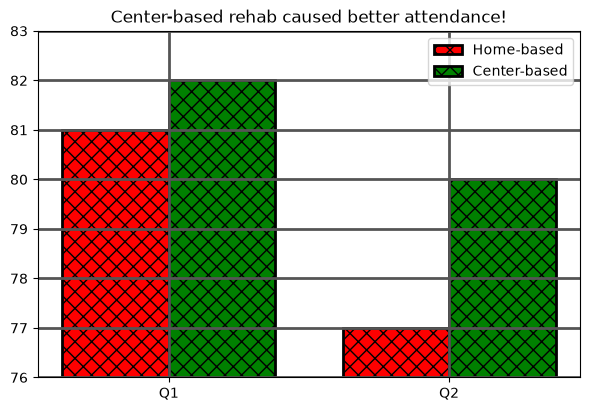

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", "problem": "The title calims causation when with no support to the claim", "repair": "Use a title that describes the data"},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", "problem": "The Y-axis starts at 76", "repair": "Make the range between each value on the Y-axis larger and have it start at zero, or signify that you are skipping value"},
    {"category": "missing unit", "problem": "The Y-axis does not say what the measurement is", "repair": "Add label to Y-axis to make it more descriptive"},
    {"category": "color-only encoding", "problem": "color-only encoding is not colorblind friendly", "repair": "Use a label to make it clear which is home or center based"},
    {"category": "distracting decoration", "problem": "The grid pattern on the bars are unnecessary", "repair": "Take out the grid pattern"},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title calims causation when with no support to the claim
    repair: Use a title that describes the data
truncated baseline: The Y-axis starts at 76
    repair: Make the range between each value on the Y-axis larger and have it start at zero, or signify that you are skipping value
missing unit: The Y-axis does not say what the measurement is
    repair: Add label to Y-axis to make it more descriptive
color-only encoding: color-only encoding is not colorblind friendly
    repair: Use a label to make it clear which is home or center based
distracting decoration: The grid pattern on the bars are unnecessary
    repair: Take out the grid pattern


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

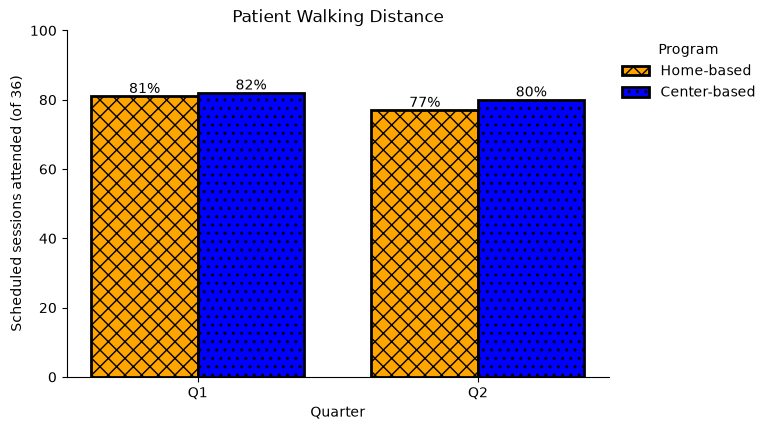

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)
quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

redesign_ax.set_ylim(0,100)
redesign_ax.set(xlabel='Quarter', ylabel='Scheduled sessions attended (of 36)', title='Patient Walking Distance')
redesign_ax.spines[['top', 'right']].set_visible(False)
home = redesign_ax.bar(x - width / 2, home, width, label="Home-based", color="ORANGE",
       hatch="xx", edgecolor="black", linewidth=2)
center = redesign_ax.bar(x + width / 2, center, width, label="Center-based", color="BLUE",
       hatch="..", edgecolor="black", linewidth=2)
redesign_ax.set_xticks(x, quarters)
redesign_ax.legend(title='Program', loc='upper left', bbox_to_anchor=(1,1), frameon=False)
redesign_ax.bar_label(home, fmt='%d%%')
redesign_ax.bar_label(center, fmt='%d%%')



# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches='tight')

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)  # TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup

question = "How well did patients do on meeting their followup goal?"  # TODO: the comparison the chart should help the coordinator make
audience = "The people conducting the sessions can use this chart to see the progress of the patients"  # TODO: who reads the chart and what they will use it for
intended_claim = "More visits is correlated with a higher goal met percentage"  # TODO: the one descriptive conclusion the chart supports
y_measure = "Percentage of goal met"  # TODO: what the y-axis measures, with its unit
grain = "The row should represent the number of visits and one point will show the goal met percentage per visit"  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "ordinal",  # TODO
    "goal_met_pct": "quantitative",  # TODO
}

supporting_data = followup[['program', 'visit_number', 'goal_met_pct']]# TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

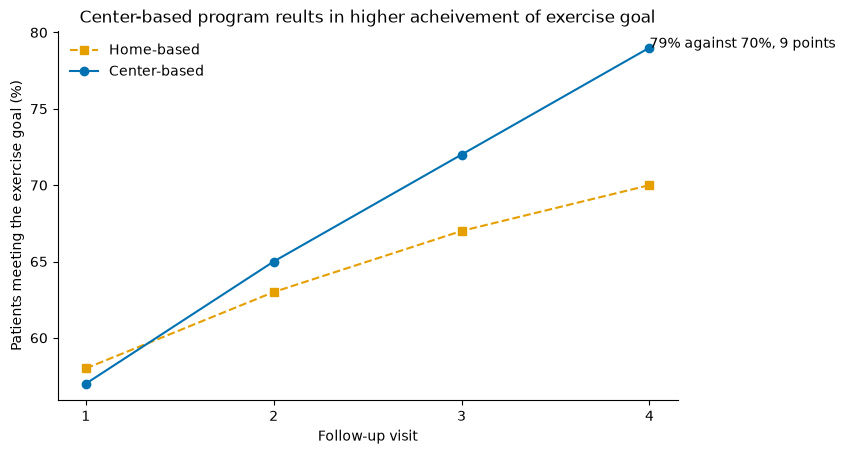

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes
explanatory_ax.set(xlabel='Follow-up visit', ylabel='Patients meeting the exercise goal (%)', title='Center-based program reults in higher acheivement of exercise goal')
explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.plot(home_goals['visit_number'], home_goals['goal_met_pct'],'s--', color=ORANGE, label='Home-based')
explanatory_ax.plot(center_goals['visit_number'], center_goals['goal_met_pct'], 'o-',color=BLUE, label='Center-based')
explanatory_ax.text(4, 79, '79% against 70%, 9 points')
explanatory_ax.spines[['top', 'right']].set_visible(False)
explanatory_ax.legend(frameon=False)

# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches='tight')

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = "This is a line graph that describes the patients' exercise goals in regards to their followup visits. The followup viist number is on the x-axis and the percentage of exercise goal reached is on the y-axis. The gap at follow up visit 4 shows a significant increase in center-based patients. patients chose their program, so the gap does not show that one program causes more exercise, and each percentage covers only the patients seen at that visit, about 45 per program, so a 9-point gap could also come from chance or from who returned"  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    'question': question,
    'audience': audience,
    'intended_claim': intended_claim,
    'y_measure': y_measure,
    'grain': grain,
    'data_types': data_types,
    'text_alternative': text_alternative,
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH
with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

    
with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

TODO: Replace this line with your answers.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m